# TEXT CLASSIFICATION BATTLE – COMPARE, ANALYZE AND DEFEND
**Course:** 21CSE377T – Information Retrieval  
**Application:** SMS/message spam detection  
**Classes:** `spam` and `ham` (legitimate message)  
**Dataset:** 100 original short messages, balanced (50 spam, 50 ham).

This notebook trains and compares Decision Tree, KNN, SVM and Naive Bayes using the same TF-IDF representation and the same stratified train-test split. Run every cell in order. The notebook contains the dataset directly, so it runs independently in Google Colab.

## 1. Import libraries and create the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

data = [('I need some help installing the Python package', 'ham'), ('Can you call me when you finish your assignment', 'ham'), ('Please check whether the computer lab is open today', 'ham'), ('Special cash reward waiting for you complete registration', 'spam'), ('Urgent claim your winning amount by replying to this message', 'spam'), ('Click this link to activate your free reward package', 'spam'), ('Exclusive investment returns guaranteed join our money scheme', 'spam'), ('I will bring the printed forms to the office', 'ham'), ('Get a guaranteed prize by sending your details to this number', 'spam'), ('Congratulations you won a free cash prize claim your reward now', 'spam'), ('Your free subscription is ready activate it using this link', 'spam'), ('Your number has won a cash reward call to claim it', 'spam'), ('The library closes at six so let us go early', 'ham'), ('Last chance to claim free gifts from our promotion', 'spam'), ('Thanks for sharing the useful study material', 'ham'), ('You have been selected for a cash bonus call this number today', 'spam'), ('Your presentation was clear and the examples were helpful', 'ham'), ('I am waiting near the main college entrance', 'ham'), ('Free entry in our lucky contest submit your phone number', 'spam'), ('Get a free shopping voucher by completing this short survey', 'spam'), ('Thanks for helping me understand the mathematics problem', 'ham'), ('Can you explain how this code produces the output', 'ham'), ('Apply now for a loan without paperwork or waiting period', 'spam'), ('Get low interest credit instantly through this online offer', 'spam'), ('I will share the meeting link in our class group', 'ham'), ('Instant credit available apply online for a quick cash loan', 'spam'), ('Hot deal buy today and receive a special cash bonus', 'spam'), ('The seminar begins at ten in the auditorium', 'ham'), ('Act fast to collect your free tickets offer ends tonight', 'spam'), ('We can take the bus together after the final lecture', 'ham'), ('Special promotion receive extra cash when you register today', 'spam'), ('Limited time discount and bonus gift shop today', 'spam'), ('Let us meet outside the cafeteria after the exam', 'ham'), ('Winner announcement collect your reward by confirming your details', 'spam'), ('We should test the program before the project demonstration', 'ham'), ('Claim your free holiday package before the special offer expires', 'spam'), ('I left my water bottle in the classroom after lunch', 'ham'), ('We need to submit the project files before Monday', 'ham'), ('Congratulations you qualify for an exclusive bonus reward', 'spam'), ('Win amazing gifts with this exclusive promotional message', 'spam'), ('Make quick money online with this simple earning offer', 'spam'), ('Instant approval cash loan available for everyone apply today', 'spam'), ('Your account won a shopping coupon click the link to redeem', 'spam'), ('I am reading the chapter and making short notes', 'ham'), ('Free mobile recharge available for selected users claim today', 'spam'), ('Final reminder claim the bonus before your account reward expires', 'spam'), ('Did you receive the photos from yesterday event', 'ham'), ('Earn extra income daily with this simple online opportunity', 'spam'), ('The teacher shared the examination timetable with everyone', 'ham'), ('Limited deal unlock a discount reward by clicking this link', 'spam'), ('Urgent notification your prize will be cancelled unless you respond', 'spam'), ('Exclusive deal get cheap loans with instant approval apply now', 'spam'), ('Get rich quickly from home register for this opportunity', 'spam'), ('Earn thousands weekly from home with our easy program', 'spam'), ('Lowest price guaranteed buy now and get a bonus gift', 'spam'), ('Remember to save a copy of the assignment document', 'ham'), ('Earn money from home with no experience sign up immediately', 'spam'), ('Could you review this paragraph for my college assignment', 'ham'), ('Receive free products by joining our promotional campaign', 'spam'), ('I will be absent today because I have an appointment', 'ham'), ('I bought groceries and will cook dinner when I get home', 'ham'), ('See you tomorrow and have a safe journey home', 'ham'), ('The project meeting has moved to Friday afternoon', 'ham'), ('Register now to unlock a free voucher and gift', 'spam'), ('Hi are we still meeting at the library after class today', 'ham'), ('Are you available to study together this weekend', 'ham'), ('Free entry available win a holiday by joining now', 'spam'), ('The weather looks cloudy so carry an umbrella outside', 'ham'), ('I enjoyed our conversation yesterday see you next week', 'ham'), ('Would you like to join us for lunch after class', 'ham'), ('The doctor asked me to return for a checkup next week', 'ham'), ('Your lucky draw result is ready collect the free prize', 'spam'), ('Let us discuss the presentation slides before the class', 'ham'), ('Congratulations your selected account can claim free cash', 'spam'), ('I finished the data collection and started the analysis', 'ham'), ('Your book is on my desk you can collect it tomorrow', 'ham'), ('Can we reschedule the call to tomorrow morning', 'ham'), ('Double your money quickly with our guaranteed investment plan', 'spam'), ('Please update the group when you reach the campus', 'ham'), ('The train is delayed so I may arrive a little late', 'ham'), ('I am working on the report and will send it tonight', 'ham'), ('The discussion was useful and I understand the topic now', 'ham'), ('Claim the prize now before this limited offer closes', 'spam'), ('Special offer save money with this limited time promotion', 'spam'), ('Urgent offer limited time click here to receive a gift voucher', 'spam'), ('I will reach home around seven after the bus ride', 'ham'), ('Buy one product and receive another item free today', 'spam'), ('Win a brand new phone today by entering this lucky draw', 'spam'), ('Click now to receive a free gift card and special discount', 'spam'), ('The bus route changed so check the updated schedule', 'ham'), ('The assignment deadline is next Thursday afternoon', 'ham'), ('I have completed the first section of our project', 'ham'), ('I have sent the document to your email address', 'ham'), ('Please tell the team that our class starts at nine', 'ham'), ('Cash prize alert you are our lucky winner respond immediately', 'spam'), ('Please remember to bring your notebook to the lab', 'ham'), ('My phone battery is low I will message you later', 'ham'), ('Congratulations customer your reward is waiting claim it now', 'spam'), ('I found your charger beside the classroom window', 'ham'), ('Please send me the notes from this morning lecture', 'ham')]
df = pd.DataFrame(data, columns=["text", "label"])
df.insert(0, "document_id", [f"M{i:03d}" for i in range(1, len(df)+1)])
print("Dataset shape:", df.shape)
print("\\nClass distribution:")
print(df["label"].value_counts())
df.head()

Dataset shape: (100, 3)
\nClass distribution:
label
ham     50
spam    50
Name: count, dtype: int64


,document_id,text,label
0,M001,I need some help installing the Python package,ham
1,M002,Can you call me when you finish your assignment,ham
2,M003,Please check whether the computer lab is open ...,ham
3,M004,Special cash reward waiting for you complete r...,spam
4,M005,Urgent claim your winning amount by replying t...,spam


## 2. Understand the dataset and split
- `spam`: unwanted/promotional message.
- `ham`: normal/legitimate message.
- We use a 75% training set and 25% testing set.
- `stratify=y` preserves the class proportion in both sets.
- `random_state=42` makes the split reproducible.

In [2]:
X = df["text"]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\\nTraining class distribution:")
print(y_train.value_counts())
print("\\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 75
Testing samples: 25
\nTraining class distribution:
label
spam    38
ham     37
Name: count, dtype: int64
\nTesting class distribution:
label
ham     13
spam    12
Name: count, dtype: int64


## 3. Text preprocessing and TF-IDF
The vectorizer converts text to lowercase, removes English stop words, tokenizes the messages and creates TF-IDF features. The same vectorizer settings and data split are used for all four classifiers. The vectorizer is inside each pipeline, so it is fitted only on training text and does not learn from the test set.

In [3]:
vectorizer_settings = dict(lowercase=True, stop_words="english", ngram_range=(1, 1))
preview_vectorizer = TfidfVectorizer(**vectorizer_settings)
X_train_tfidf = preview_vectorizer.fit_transform(X_train)
print("Number of TF-IDF features:", len(preview_vectorizer.get_feature_names_out()))
print("TF-IDF training matrix shape:", X_train_tfidf.shape)
print("Sample vocabulary:", preview_vectorizer.get_feature_names_out()[:20])

Number of TF-IDF features: 234
TF-IDF training matrix shape: (75, 234)
Sample vocabulary: ['account' 'activate' 'address' 'afternoon' 'alert' 'amazing' 'analysis'
 'apply' 'approval' 'arrive' 'asked' 'assignment' 'auditorium' 'available'
 'battery' 'begins' 'bonus' 'book' 'bottle' 'bring']


## 4. Train four classifiers and evaluate them
Metrics are calculated on the same held-out test set. Precision, recall and F1-score use `spam` as the positive class.

In [4]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=20),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42, max_iter=5000),
    "Naive Bayes": MultinomialNB()
}

pipelines = {}
predictions = {}
rows = []

for name, classifier in classifiers.items():
    model = Pipeline([
        ("tfidf", TfidfVectorizer(**vectorizer_settings)),
        ("classifier", classifier)
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    pipelines[name] = model
    predictions[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(y_test, y_pred, pos_label="spam", zero_division=0),
        "Recall (spam)": recall_score(y_test, y_pred, pos_label="spam", zero_division=0),
        "F1-score (spam)": f1_score(y_test, y_pred, pos_label="spam", zero_division=0)
    })

comparison = pd.DataFrame(rows).sort_values("F1-score (spam)", ascending=False)
comparison

,Model,Accuracy,Precision (spam),Recall (spam),F1-score (spam)
2,SVM,0.96,0.923077,1.0,0.960000
3,Naive Bayes,0.88,0.800000,1.0,0.888889
1,KNN (k=5),0.72,0.631579,1.0,0.774194
0,Decision Tree,0.72,0.857143,0.5,0.631579


## 5. Comparative graph

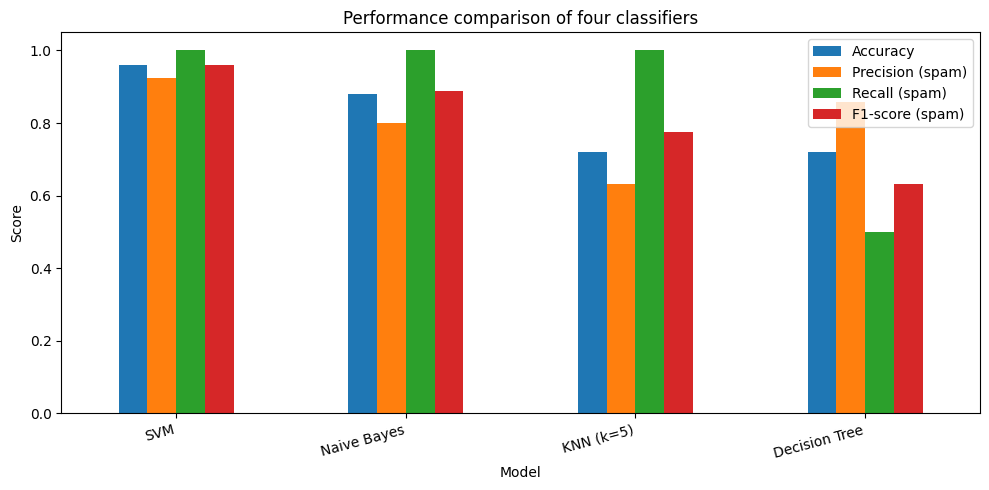

In [5]:
metrics = ["Accuracy", "Precision (spam)", "Recall (spam)", "F1-score (spam)"]
ax = comparison.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 5))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Performance comparison of four classifiers")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 6. Confusion matrices and classification reports
A confusion matrix shows correct and incorrect predictions for each class. Rows are actual labels and columns are predicted labels.

\n Decision Tree
              precision    recall  f1-score   support

         ham       0.67      0.92      0.77        13
        spam       0.86      0.50      0.63        12

    accuracy                           0.72        25
   macro avg       0.76      0.71      0.70        25
weighted avg       0.76      0.72      0.71        25



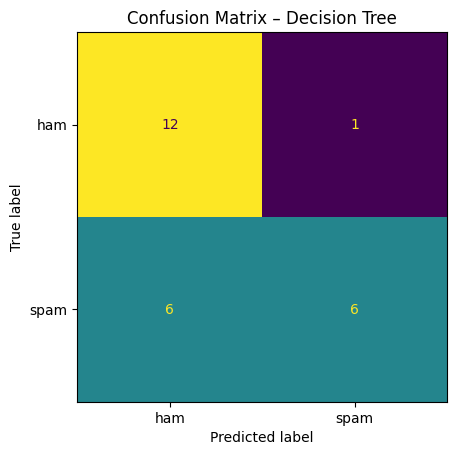

\n KNN (k=5)
              precision    recall  f1-score   support

         ham       1.00      0.46      0.63        13
        spam       0.63      1.00      0.77        12

    accuracy                           0.72        25
   macro avg       0.82      0.73      0.70        25
weighted avg       0.82      0.72      0.70        25



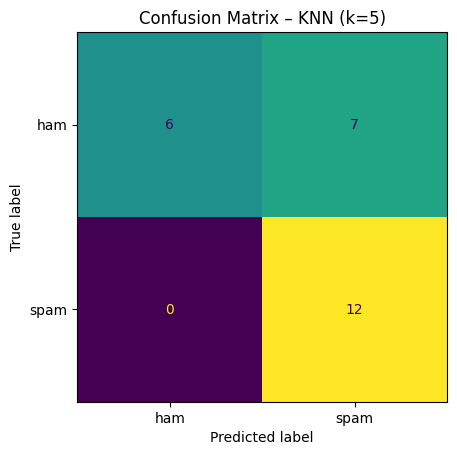

\n SVM
              precision    recall  f1-score   support

         ham       1.00      0.92      0.96        13
        spam       0.92      1.00      0.96        12

    accuracy                           0.96        25
   macro avg       0.96      0.96      0.96        25
weighted avg       0.96      0.96      0.96        25



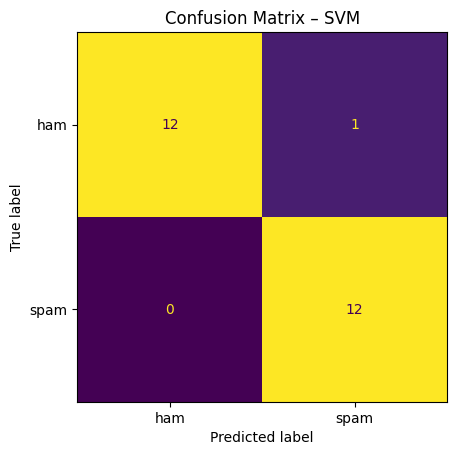

\n Naive Bayes
              precision    recall  f1-score   support

         ham       1.00      0.77      0.87        13
        spam       0.80      1.00      0.89        12

    accuracy                           0.88        25
   macro avg       0.90      0.88      0.88        25
weighted avg       0.90      0.88      0.88        25



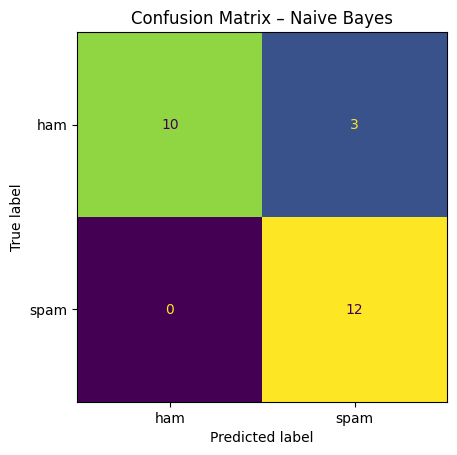

In [7]:
for name, y_pred in predictions.items():
    print("\\n", name)
    print(classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"])
    disp.plot(values_format="d", colorbar=False)
    plt.title(f"Confusion Matrix – {name}")
    plt.show()

## 7. What-if analysis: change K in KNN
We keep the same training/test split and TF-IDF settings, and change only the number of neighbours (`k`) to 3, 5, 7 and 9. Compare the scores to see how this parameter affects predictions.

In [6]:
what_if_rows = []
for k in [3, 5, 7, 9]:
    knn_model = Pipeline([
        ("tfidf", TfidfVectorizer(**vectorizer_settings)),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    knn_model.fit(X_train, y_train)
    pred = knn_model.predict(X_test)
    what_if_rows.append({
        "K value": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (spam)": precision_score(y_test, pred, pos_label="spam", zero_division=0),
        "Recall (spam)": recall_score(y_test, pred, pos_label="spam", zero_division=0),
        "F1-score (spam)": f1_score(y_test, pred, pos_label="spam", zero_division=0)
    })
what_if = pd.DataFrame(what_if_rows)
what_if

,K value,Accuracy,Precision (spam),Recall (spam),F1-score (spam)
0,3,0.80,0.705882,1.0,0.827586
1,5,0.72,0.631579,1.0,0.774194
2,7,0.56,0.521739,1.0,0.685714
3,9,0.60,0.545455,1.0,0.705882


## 8. Test the classifier with new messages
Choose one fitted classifier and try your own messages. This is a demonstration, not a guarantee that every real-world spam message will be detected.

In [8]:
best_model_name = comparison.iloc[0]["Model"]
best_model = pipelines[best_model_name]
sample_messages = [
    "Congratulations claim your free cash reward now",
    "Hi please bring the notes to class tomorrow"
]
print("Selected model:", best_model_name)
for message, prediction in zip(sample_messages, best_model.predict(sample_messages)):
    print(f"Message: {message}\\nPredicted class: {prediction}\\n")

Selected model: SVM
Message: Congratulations claim your free cash reward now\nPredicted class: spam\n
Message: Hi please bring the notes to class tomorrow\nPredicted class: ham\n


## 9. Save outputs
Run this cell to export the dataset, model comparison, and KNN what-if table as CSV files.

In [9]:
df.to_csv("messages_dataset.csv", index=False)
comparison.to_csv("model_comparison.csv", index=False)
what_if.to_csv("knn_what_if.csv", index=False)
print("CSV output files saved.")

CSV output files saved.


## 10. Conclusion
Compare the actual scores from your run. Identify the best model using the chosen metric, explain the confusion matrix, and discuss why model behaviour differs. The dataset is a small original teaching dataset; real-world spam detection requires a larger, more diverse dataset and additional validation.

**Before submission:** Run the notebook yourself, save screenshots of the outputs, read the results rather than copying expected claims, and practise explaining the four algorithms and the KNN what-if experiment.